# 00. 전력 파형과 트리거

같은 마이크로컨트롤러라도 실행하는 코드가 달라지면 전력 파형도 달라집니다. 이번 실습에서는 트리거로 연산 시작점을 맞춘 뒤 NOP, 곱셈, AES 파형을 비교합니다.

여기서 사용하는 데이터는 원리를 설명하려고 만든 합성 파형입니다. 실제 장치에서 누설을 측정한 결과는 아닙니다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cw_sca_tutorial.synthetic import make_operation_dataset

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})
traces, labels = make_operation_dataset()
print(f"파형 {traces.shape[0]}개 × 샘플 {traces.shape[1]}개")

파형 36개 × 샘플 500개


## 개별 파형과 평균

얇은 선은 개별 파형이고 굵은 선은 같은 연산을 여러 번 평균한 결과입니다. 모든 파형의 트리거를 샘플 0에 맞췄으므로 같은 연산 구간이 겹쳐 보입니다.

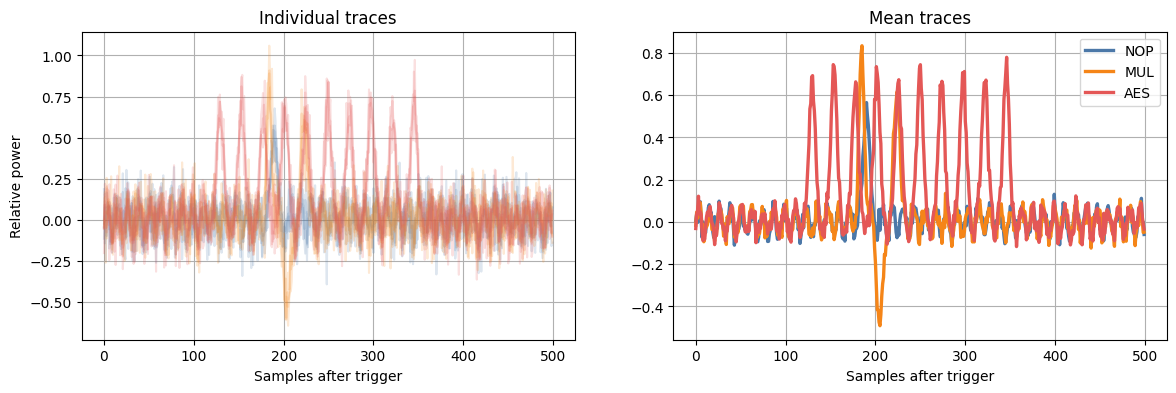

In [2]:
colors = {"NOP": "#4c78a8", "MUL": "#f58518", "AES": "#e45756"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for label in ("NOP", "MUL", "AES"):
    group = traces[labels == label]
    axes[0].plot(group[:4].T, color=colors[label], alpha=0.18)
    axes[1].plot(group.mean(axis=0), color=colors[label], linewidth=2.4, label=label)
axes[0].set(title="Individual traces", xlabel="Samples after trigger", ylabel="Relative power")
axes[1].set(title="Mean traces", xlabel="Samples after trigger")
axes[1].legend()
plt.show()

## Heatmap으로 보기

아래 heatmap의 한 행이 한 번의 실행입니다. AES에서는 반복되는 라운드가 보이고, MUL에서는 짧은 활동이 몇 차례 나타납니다. SPA(Simple Power Analysis)는 이런 큰 구조를 파형에서 직접 읽는 분석입니다.

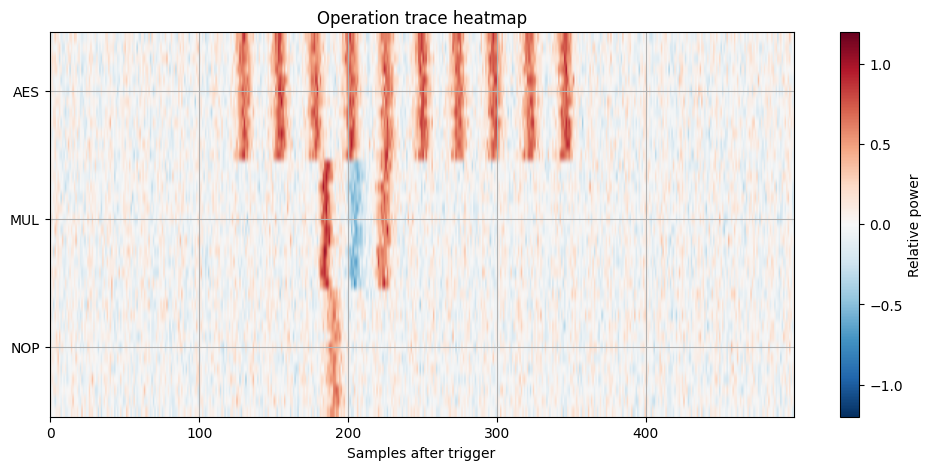

In [3]:
order = np.argsort(labels)
plt.figure(figsize=(12, 5))
plt.imshow(traces[order], aspect="auto", cmap="RdBu_r", vmin=-1.2, vmax=1.2)
plt.colorbar(label="Relative power")
plt.yticks([5, 17, 29], ["AES", "MUL", "NOP"])
plt.xlabel("Samples after trigger")
plt.title("Operation trace heatmap")
plt.show()

## 정리

트리거는 반복 측정의 시간축을 맞추고 평균은 잡음을 줄입니다. 다음 노트북에서는 조기 종료가 비밀번호 비교 횟수를 어떻게 드러내는지 살펴보겠습니다.